run 0 to 4s for client 2, then 3, then 4, then 5, then run cell 7 8.
if i want after, i can do the local 30 epochs training on client 2 3 4 5 for baseline comparison (baseline already computed for client 1)

In [1]:
# CELL 0 — CONFIG
# !! ONLY CHANGE CLIENT_ID — NOTHING ELSE !!
# ============================================================
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
import json
import random
import warnings
warnings.filterwarnings('ignore')

# ── ONLY CHANGE THIS ─────────────────────────────────────────
CLIENT_ID = 2   # change to 3, 4, or 5

OUT_ROOT = Path(r'C:\Users\Administrator\desktop\unet')

FEDERATION_SPLITS = OUT_ROOT / 'federation_splits.json'
assert FEDERATION_SPLITS.exists()
with open(FEDERATION_SPLITS) as f:
    fed_splits = json.load(f)
CLIENT_PIDS = fed_splits[f'client{CLIENT_ID}_pids']

CLIENT_DIR   = OUT_ROOT   / f'client{CLIENT_ID}'
PREPROC_DIR  = CLIENT_DIR / 'preprocessed'
MASK_DIR     = CLIENT_DIR / 'lung_masks'
ANNOT_DIR    = CLIENT_DIR / 'annotations'
PATCH_DIR    = CLIENT_DIR / 'patches' / f'client{CLIENT_ID}'
WEIGHTS_DIR  = CLIENT_DIR / 'weights'
LOG_DIR      = CLIENT_DIR / 'logs'
GLOBAL_TEST_MANIFEST = OUT_ROOT / 'global_test_pids.json'

for d in [PREPROC_DIR, MASK_DIR, ANNOT_DIR,
          PATCH_DIR / 'positives',
          PATCH_DIR / 'negatives',
          WEIGHTS_DIR, LOG_DIR]:
    d.mkdir(parents=True, exist_ok=True)

PATCH_SIZE            = 96
STRIDE                = 20
BATCH_SIZE            = 4
N_EPOCHS              = 30
PATIENCE              = 8
N_JITTERS             = 4
LR                    = 1e-4
NEG_POS_RATIO         = 2
MIN_CONSENSUS         = 3
MARGIN_VOXELS         = 10
BASE_FILTERS          = 32
GAUSSIAN_SIGMA_FACTOR = 3
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

print(f'Client      : {CLIENT_ID}')
print(f'Patients    : {len(CLIENT_PIDS)}')
print(f'Device      : {DEVICE}')
print(f'Client dir  : {CLIENT_DIR}')
print(f'Preprocessed: {PREPROC_DIR}')
print(f'Masks       : {MASK_DIR}')
print(f'Annotations : {ANNOT_DIR}')
print(f'Patches     : {PATCH_DIR}')
print(f'Weights     : {WEIGHTS_DIR}')
print(f'Logs        : {LOG_DIR}')
print(f'First 5 PIDs: {CLIENT_PIDS[:5]}')
print(f'Last  5 PIDs: {CLIENT_PIDS[-5:]}')


Client      : 2
Patients    : 180
Device      : cuda
Client dir  : C:\Users\Administrator\desktop\unet\client2
Preprocessed: C:\Users\Administrator\desktop\unet\client2\preprocessed
Masks       : C:\Users\Administrator\desktop\unet\client2\lung_masks
Annotations : C:\Users\Administrator\desktop\unet\client2\annotations
Patches     : C:\Users\Administrator\desktop\unet\client2\patches\client2
Weights     : C:\Users\Administrator\desktop\unet\client2\weights
Logs        : C:\Users\Administrator\desktop\unet\client2\logs
First 5 PIDs: ['LIDC-IDRI-0161', 'LIDC-IDRI-0162', 'LIDC-IDRI-0163', 'LIDC-IDRI-0164', 'LIDC-IDRI-0165']
Last  5 PIDs: ['LIDC-IDRI-0344', 'LIDC-IDRI-0345', 'LIDC-IDRI-0348', 'LIDC-IDRI-0349', 'LIDC-IDRI-0350']


In [2]:
# CELL 1 — PREPROCESSING
# Resample raw DICOM to 1mm³, normalize HU to [0,1]
# Skips already processed patients
# Runtime: ~15-25 min
# Writes: PREPROC_DIR/<pid>.npy + <pid>_meta.npy
# ============================================================
import SimpleITK as sitk
import pylidc as pl
from tqdm import tqdm

if not hasattr(np, 'int'):
    np.int = int

HU_MIN = -1000.0
HU_MAX =  400.0

all_scans = pl.query(pl.Scan).order_by(pl.Scan.patient_id).all()
seen = {}
for s in all_scans:
    if s.patient_id not in seen:
        seen[s.patient_id] = s

client_scans = [seen[pid] for pid in CLIENT_PIDS if pid in seen]
print(f'Scans found: {len(client_scans)}/{len(CLIENT_PIDS)}')

failed = []
skipped = 0

for scan in tqdm(client_scans, desc=f'C{CLIENT_ID} preprocess'):
    pid      = scan.patient_id
    out_vol  = PREPROC_DIR / f'{pid}.npy'
    out_meta = PREPROC_DIR / f'{pid}_meta.npy'
    if out_vol.exists() and out_meta.exists():
        skipped += 1
        continue
    try:
        dicom_path = scan.get_path_to_dicom_files()
        ids   = sitk.ImageSeriesReader.GetGDCMSeriesIDs(str(dicom_path))
        files = sitk.ImageSeriesReader.GetGDCMSeriesFileNames(str(dicom_path), ids[0])
        reader = sitk.ImageSeriesReader()
        reader.SetFileNames(files)
        sitk_img = reader.Execute()
        orig_spacing = sitk_img.GetSpacing()
        orig_size    = sitk_img.GetSize()
        new_size = [int(round(orig_size[i] * orig_spacing[i])) for i in range(3)]
        resampler = sitk.ResampleImageFilter()
        resampler.SetOutputSpacing([1.0, 1.0, 1.0])
        resampler.SetSize(new_size)
        resampler.SetOutputDirection(sitk_img.GetDirection())
        resampler.SetOutputOrigin(sitk_img.GetOrigin())
        resampler.SetTransform(sitk.Transform())
        resampler.SetDefaultPixelValue(-1000)
        resampler.SetInterpolator(sitk.sitkLinear)
        sitk_res = resampler.Execute(sitk_img)
        vol = sitk.GetArrayFromImage(sitk_res).astype(np.float32)
        vol = np.clip(vol, HU_MIN, HU_MAX)
        vol = (vol - HU_MIN) / (HU_MAX - HU_MIN)
        np.save(out_vol, vol)
        meta = {
            'res_size'      : sitk_res.GetSize(),
            'res_spacing'   : sitk_res.GetSpacing(),
            'res_origin'    : sitk_res.GetOrigin(),
            'res_direction' : sitk_res.GetDirection(),
            'orig_size'     : sitk_img.GetSize(),
            'orig_spacing'  : sitk_img.GetSpacing(),
            'orig_origin'   : sitk_img.GetOrigin(),
            'orig_direction': sitk_img.GetDirection(),
        }
        np.save(out_meta, meta)
    except Exception as e:
        print(f'\n  ERROR {pid}: {e}')
        failed.append(pid)

print(f'\nDone. Processed={len(client_scans)-len(failed)-skipped}'
      f'  Skipped={skipped}  Failed={len(failed)}')
if failed:
    print(f'Failed: {failed}')


Scans found: 180/180


C2 preprocess: 100%|█████████████████████████████████████████████████████████████████| 180/180 [14:19<00:00,  4.77s/it]


Done. Processed=180  Skipped=0  Failed=0


In [3]:
# CELL 2 — LUNG MASK GENERATION
# Same approach as client 1:
#   1. Load raw DICOM (original spacing)
#   2. Run lungmask R231 on raw DICOM
#   3. Resample mask to 1mm³ using nearest neighbour
#   4. Match shape to preprocessed volume exactly
# Skips already processed patients
# Runtime: ~25-35 min
# Writes: MASK_DIR/<pid>.npy  (binary uint8, 1=lung)
# ============================================================
from lungmask import LMInferer

inferer = LMInferer(modelname='R231')
print(f'Lungmask R231 loaded')

failed_mask  = []
skipped_mask = 0

for scan in tqdm(client_scans, desc=f'C{CLIENT_ID} masks'):
    pid      = scan.patient_id
    out_mask = MASK_DIR    / f'{pid}.npy'
    vol_path = PREPROC_DIR / f'{pid}.npy'
    if out_mask.exists():
        skipped_mask += 1
        continue
    if not vol_path.exists():
        print(f'\n  SKIP {pid} — preprocessed vol missing')
        failed_mask.append(pid)
        continue
    try:
        dicom_path = scan.get_path_to_dicom_files()
        ids   = sitk.ImageSeriesReader.GetGDCMSeriesIDs(str(dicom_path))
        files = sitk.ImageSeriesReader.GetGDCMSeriesFileNames(str(dicom_path), ids[0])
        reader = sitk.ImageSeriesReader()
        reader.SetFileNames(files)
        sitk_img = reader.Execute()  # raw DICOM, original spacing
        seg       = inferer.apply(sitk_img)  # lungmask on raw DICOM
        mask_orig = (seg > 0).astype(np.uint8)
        mask_sitk = sitk.GetImageFromArray(mask_orig)
        mask_sitk.SetSpacing(sitk_img.GetSpacing())
        mask_sitk.SetOrigin(sitk_img.GetOrigin())
        mask_sitk.SetDirection(sitk_img.GetDirection())
        orig_size    = sitk_img.GetSize()
        orig_spacing = sitk_img.GetSpacing()
        new_size = [int(round(orig_size[i] * orig_spacing[i])) for i in range(3)]
        resampler = sitk.ResampleImageFilter()
        resampler.SetOutputSpacing([1.0, 1.0, 1.0])
        resampler.SetSize(new_size)
        resampler.SetOutputDirection(sitk_img.GetDirection())
        resampler.SetOutputOrigin(sitk_img.GetOrigin())
        resampler.SetTransform(sitk.Transform())
        resampler.SetDefaultPixelValue(0)
        resampler.SetInterpolator(sitk.sitkNearestNeighbor)
        mask_resampled = sitk.GetArrayFromImage(
            resampler.Execute(mask_sitk)).astype(np.uint8)
        vol_shape = np.load(vol_path).shape
        if mask_resampled.shape != vol_shape:
            mask_resampled = mask_resampled[
                :vol_shape[0], :vol_shape[1], :vol_shape[2]]
            if mask_resampled.shape != vol_shape:
                pad = [(0, max(0, vol_shape[i]-mask_resampled.shape[i]))
                       for i in range(3)]
                mask_resampled = np.pad(mask_resampled, pad, mode='constant')
        np.save(out_mask, mask_resampled)
    except Exception as e:
        print(f'\n  ERROR {pid}: {e}')
        failed_mask.append(pid)

print(f'\nDone. Processed={len(client_scans)-len(failed_mask)-skipped_mask}'
      f'  Skipped={skipped_mask}  Failed={len(failed_mask)}')

# shape verification
print('\nVerifying shape match (first 5)...')
errors = 0
for pid in CLIENT_PIDS[:5]:
    mp = MASK_DIR    / f'{pid}.npy'
    vp = PREPROC_DIR / f'{pid}.npy'
    if mp.exists() and vp.exists():
        ms = np.load(mp).shape
        vs = np.load(vp).shape
        ok = '✓' if ms == vs else '✗ MISMATCH'
        if ms != vs: errors += 1
        print(f'  {pid}: mask={ms} vol={vs} {ok}')
if errors == 0:
    print('All shapes match ✓')


Lungmask R231 loaded


C2 masks:   0%|                                                                                | 0/180 [00:00<?, ?it/s]
  0%|                                                                                        | 0/12.55 [00:00<?, ?it/s]
  8%|██████▎                                                                         | 1/12.55 [00:13<02:41, 13.95s/it]
 16%|████████████▋                                                                   | 2/12.55 [00:14<01:01,  5.83s/it]
 24%|███████████████████                                                             | 3/12.55 [00:14<00:30,  3.23s/it]
 32%|█████████████████████████▍                                                      | 4/12.55 [00:14<00:17,  2.02s/it]
 40%|███████████████████████████████▊                                                | 5/12.55 [00:14<00:10,  1.34s/it]
 48%|██████████████████████████████████████▏                                         | 6/12.55 [00:14<00:06,  1.07it/s]
 56%|███████████████████████████████████

lungmask 2026-04-03 11:16:23 Postprocessing




C2 masks:   1%|▍                                                                     | 1/180 [00:26<1:19:33, 26.67s/it]
  0%|                                                                                         | 0/6.65 [00:00<?, ?it/s]
 15%|████████████▏                                                                    | 1/6.65 [00:00<00:00,  7.07it/s]
 30%|████████████████████████▎                                                        | 2/6.65 [00:00<00:00,  6.98it/s]
 45%|████████████████████████████████████▌                                            | 3/6.65 [00:00<00:00,  6.97it/s]
 60%|████████████████████████████████████████████████▋                                | 4/6.65 [00:00<00:00,  6.96it/s]
 75%|████████████████████████████████████████████████████████████▉                    | 5/6.65 [00:00<00:00,  6.96it/s]
105%|████████████████████████████████████████████████████████████████████████████████| 7/6.65 [00:00<-00:00,  7.27it/s]

lungmask 2026-04-03 11:16:32 Postprocessing


...

lungmask 2026-04-03 11:46:46 Postprocessing




C2 masks:  99%|█████████████████████████████████████████████████████████████████████▌| 179/180 [30:48<00:11, 11.49s/it]
  0%|                                                                                         | 0/13.5 [00:00<?, ?it/s]
  7%|██████                                                                           | 1/13.5 [00:00<00:01,  7.05it/s]
 15%|████████████                                                                     | 2/13.5 [00:00<00:01,  6.98it/s]
 22%|██████████████████                                                               | 3/13.5 [00:00<00:01,  6.91it/s]
 30%|████████████████████████                                                         | 4/13.5 [00:00<00:01,  6.92it/s]
 37%|██████████████████████████████                                                   | 5/13.5 [00:00<00:01,  6.93it/s]
 44%|████████████████████████████████████                                             | 6/13.5 [00:00<00:01,  6.94it/s]
 52%|█████████████████████████████████

lungmask 2026-04-03 11:46:58 Postprocessing




C2 masks: 100%|██████████████████████████████████████████████████████████████████████| 180/180 [31:02<00:00, 10.35s/it]



Done. Processed=180  Skipped=0  Failed=0

Verifying shape match (first 5)...
  LIDC-IDRI-0161: mask=(314, 420, 420) vol=(314, 420, 420) ✓
  LIDC-IDRI-0162: mask=(332, 400, 400) vol=(332, 400, 400) ✓
  LIDC-IDRI-0163: mask=(332, 360, 360) vol=(332, 360, 360) ✓
  LIDC-IDRI-0164: mask=(322, 440, 440) vol=(322, 440, 440) ✓
  LIDC-IDRI-0165: mask=(332, 360, 360) vol=(332, 360, 360) ✓
All shapes match ✓


In [4]:
# CELL 3 — ANNOTATION EXTRACTION
# pylidc → resampled 1mm³ voxel coordinates
# Skips already processed patients
# Runtime: ~5-10 min
# Writes: ANNOT_DIR/<pid>.json
# ============================================================

def get_nodule_center_resampled(ann, sitk_orig, sitk_res):
    bbox     = ann.bbox()
    orig_col = (bbox[1].start + bbox[1].stop) // 2
    orig_row = (bbox[0].start + bbox[0].stop) // 2
    orig_k   = (bbox[2].start + bbox[2].stop) // 2
    phys     = sitk_orig.TransformIndexToPhysicalPoint(
        (int(orig_col), int(orig_row), int(orig_k)))
    res_idx  = sitk_res.TransformPhysicalPointToIndex(phys)
    size     = sitk_res.GetSize()
    return [
        int(max(0, min(size[2]-1, res_idx[2]))),
        int(max(0, min(size[1]-1, res_idx[1]))),
        int(max(0, min(size[0]-1, res_idx[0]))),
    ]

def get_nodule_radius_mm(ann_group):
    diameters = []
    for ann in ann_group:
        try:
            diameters.append(ann.diameter)
        except Exception:
            bbox = ann.bbox()
            diameters.append(((bbox[0].stop-bbox[0].start)+
                              (bbox[1].stop-bbox[1].start))/2.0)
    return float(np.mean(diameters)) / 2.0

def load_sitk_orig(scan):
    dicom_path = scan.get_path_to_dicom_files()
    ids   = sitk.ImageSeriesReader.GetGDCMSeriesIDs(str(dicom_path))
    files = sitk.ImageSeriesReader.GetGDCMSeriesFileNames(str(dicom_path), ids[0])
    reader = sitk.ImageSeriesReader()
    reader.SetFileNames(files)
    return reader.Execute()

def build_sitk_res(pid):
    meta = np.load(PREPROC_DIR / f'{pid}_meta.npy', allow_pickle=True).item()
    s = sitk.Image([int(x) for x in meta['res_size']], sitk.sitkFloat32)
    s.SetSpacing([float(x) for x in meta['res_spacing']])
    s.SetOrigin([float(x) for x in meta['res_origin']])
    s.SetDirection([float(x) for x in meta['res_direction']])
    return s

failed_annot     = []
skipped_annot    = 0
total_consensus  = 0
total_ambiguous  = 0
patients_no_nods = 0

for scan in tqdm(client_scans, desc=f'C{CLIENT_ID} annotations'):
    pid      = scan.patient_id
    out_path = ANNOT_DIR / f'{pid}.json'
    if out_path.exists():
        skipped_annot += 1
        continue
    try:
        sitk_orig  = load_sitk_orig(scan)
        sitk_res   = build_sitk_res(pid)
        nod_groups = scan.cluster_annotations()
        consensus_nodules = []
        exclusion_zones   = []
        for ann_group in nod_groups:
            center = get_nodule_center_resampled(ann_group[0], sitk_orig, sitk_res)
            radius = get_nodule_radius_mm(ann_group)
            mal_scores = [ann.malignancy for ann in ann_group if ann.malignancy is not None]
            malignancy = float(np.mean(mal_scores)) if mal_scores else None
            exclusion_zones.append({'center_res': center, 'radius_mm': round(radius, 2)})
            if len(ann_group) >= MIN_CONSENSUS:
                consensus_nodules.append({
                    'center_res'  : center,
                    'radius_mm'   : round(radius, 2),
                    'malignancy'  : round(malignancy, 2) if malignancy else None,
                    'n_annotators': len(ann_group)
                })
                total_consensus += 1
            else:
                total_ambiguous += 1
        if len(consensus_nodules) == 0:
            patients_no_nods += 1
        with open(out_path, 'w') as f:
            json.dump({
                'patient_id'          : pid,
                'n_consensus_nodules' : len(consensus_nodules),
                'n_exclusion_zones'   : len(exclusion_zones),
                'consensus_nodules'   : consensus_nodules,
                'exclusion_zones'     : exclusion_zones
            }, f, indent=2)
    except Exception as e:
        print(f'\n  ERROR {pid}: {e}')
        failed_annot.append(pid)

print(f'\nDone.')
print(f'  Processed        : {len(client_scans)-len(failed_annot)-skipped_annot}')
print(f'  Skipped          : {skipped_annot}')
print(f'  Failed           : {len(failed_annot)}')
print(f'  Consensus nodules: {total_consensus}')
print(f'  Ambiguous        : {total_ambiguous}')
print(f'  Clean patients   : {patients_no_nods}')


C2 annotations:  24%|███████████████▉                                                 | 44/180 [01:37<04:18,  1.90s/it]

Failed to reduce all groups to <= 4 Annotations.
Some nodules may be close and must be grouped manually.


C2 annotations:  51%|████████████████████████████████▊                                | 91/180 [03:11<02:50,  1.91s/it]

Failed to reduce all groups to <= 4 Annotations.
Some nodules may be close and must be grouped manually.


C2 annotations:  95%|████████████████████████████████████████████████████████████▊   | 171/180 [06:49<00:25,  2.83s/it]

Failed to reduce all groups to <= 4 Annotations.
Some nodules may be close and must be grouped manually.


C2 annotations: 100%|████████████████████████████████████████████████████████████████| 180/180 [07:19<00:00,  2.44s/it]


Done.
  Processed        : 180
  Skipped          : 0
  Failed           : 0
  Consensus nodules: 222
  Ambiguous        : 152
  Clean patients   : 53


In [5]:
# CELL 4 — PATCH EXTRACTION
# Extracts centered positives + negatives
# Skips existing files
# Runtime: ~20-30 min
# Writes: PATCH_DIR/positives/<pid>_n<i>_j00.npz
#         PATCH_DIR/negatives/<pid>_neg<j>.npz
# ============================================================
from scipy.ndimage import gaussian_filter

POS_DIR = PATCH_DIR / 'positives'
NEG_DIR = PATCH_DIR / 'negatives'
p       = PATCH_SIZE
ph      = p // 2
np.random.seed(42)

def make_gaussian_heatmap(patch_size, center, radius_mm,
                           sigma_factor=3, min_sigma=3.0):
    p_    = patch_size
    sigma = max(min_sigma, radius_mm / sigma_factor)
    heat  = np.zeros((p_,p_,p_), dtype=np.float32)
    cz = max(0, min(p_-1, center[0]))
    cy = max(0, min(p_-1, center[1]))
    cx = max(0, min(p_-1, center[2]))
    heat[cz,cy,cx] = 1.0
    heat = gaussian_filter(heat, sigma=sigma)
    if heat.max() > 0:
        heat = heat / heat.max()
    return heat

def extract_patch(vol, cz, cy, cx, patch_size):
    p_   = patch_size // 2
    D,H,W = vol.shape
    z1,z2 = cz-p_, cz+p_
    y1,y2 = cy-p_, cy+p_
    x1,x2 = cx-p_, cx+p_
    pz0=max(0,-z1); pz1=max(0,z2-D)
    py0=max(0,-y1); py1=max(0,y2-H)
    px0=max(0,-x1); px1=max(0,x2-W)
    crop = vol[max(0,z1):min(D,z2), max(0,y1):min(H,y2), max(0,x1):min(W,x2)]
    return np.pad(crop, ((pz0,pz1),(py0,py1),(px0,px1)),
                  mode='constant', constant_values=0).astype(np.float32)

def build_excl_mask(vol_shape, exclusion_zones, margin):
    D,H,W = vol_shape
    excl  = np.zeros((D,H,W), dtype=bool)
    for zone in exclusion_zones:
        z,y,x = zone['center_res']
        r     = int(zone['radius_mm']) + margin
        excl[max(0,z-r):min(D,z+r),
             max(0,y-r):min(H,y+r),
             max(0,x-r):min(W,x+r)] = True
    return excl

for scan in tqdm(client_scans, desc=f'C{CLIENT_ID} patches'):
    pid = scan.patient_id
    vp  = PREPROC_DIR / f'{pid}.npy'
    mp  = MASK_DIR    / f'{pid}.npy'
    ap  = ANNOT_DIR   / f'{pid}.json'
    if not (vp.exists() and mp.exists() and ap.exists()):
        continue
    vol  = np.load(vp)
    mask = np.load(mp)
    D,H,W = vol.shape
    with open(ap) as f:
        record = json.load(f)
    consensus  = record['consensus_nodules']
    exclusions = record['exclusion_zones']
    try:
        for i, nod in enumerate(consensus):
            z,y,x = nod['center_res']
            radius_mm = nod['radius_mm']
            out = POS_DIR / f'{pid}_n{i:02d}_j00.npz'
            if out.exists(): continue
            patch = extract_patch(vol, z, y, x, p)
            heat  = make_gaussian_heatmap(p, (ph,ph,ph), radius_mm, GAUSSIAN_SIGMA_FACTOR, 3.0)
            np.savez_compressed(out, vol=patch, heatmap=heat,
                                center=np.array([z,y,x]),
                                radius=np.array([radius_mm]),
                                jitter=np.array([0,0,0]))
        excl   = build_excl_mask(vol.shape, exclusions, MARGIN_VOXELS)
        valid  = (mask == 1) & ~excl
        valid[:ph,:,:]=False; valid[D-ph:,:,:]=False
        valid[:,:ph,:]=False; valid[:,H-ph:,:]=False
        valid[:,:,:ph]=False; valid[:,:,W-ph:]=False
        coords = np.argwhere(valid)
        if len(coords) == 0: continue
        n_pos    = max(len(consensus), 1)
        n_sample = min(n_pos * NEG_POS_RATIO if len(consensus) > 0 else 5, len(coords))
        chosen   = np.random.choice(len(coords), n_sample, replace=False)
        for j, idx in enumerate(chosen):
            z,y,x = coords[idx]
            out   = NEG_DIR / f'{pid}_neg{j:03d}.npz'
            if out.exists(): continue
            patch = extract_patch(vol, z, y, x, p)
            np.savez_compressed(out, vol=patch,
                                heatmap=np.zeros((p,p,p), dtype=np.float32),
                                center=np.array([z,y,x]))
    except Exception as e:
        print(f'\n  ERROR {pid}: {e}')

print(f'\nDone.')
print(f'  Positives: {len(list(POS_DIR.glob("*.npz")))}')
print(f'  Negatives: {len(list(NEG_DIR.glob("*.npz")))}')


C2 patches: 100%|████████████████████████████████████████████████████████████████████| 180/180 [07:25<00:00,  2.47s/it]


Done.
  Positives: 222
  Negatives: 709


In [6]:
# CELL 4J — JITTER
# Delete centered patches, regenerate with spatial offsets
# jitter_range = max(nodule_radius, 20mm) capped at 40mm
# Training coverage: max offset = 40mm > stride/2 = 10mm ✓
# Runtime: ~8-12 min
# Writes: PATCH_DIR/positives/<pid>_n<i>_j<ji>.npz
# ============================================================
POS_DIR = PATCH_DIR / 'positives'
NEG_DIR = PATCH_DIR / 'negatives'

existing_pos = list(POS_DIR.glob('*.npz'))
print(f'Deleting {len(existing_pos)} existing positive patches...')
for f in existing_pos:
    f.unlink()
print('Deleted.\n')

np.random.seed(42)
centered_count = 0
jittered_count = 0
all_offsets    = []

for scan in tqdm(client_scans, desc=f'C{CLIENT_ID} jitter'):
    pid = scan.patient_id
    vp  = PREPROC_DIR / f'{pid}.npy'
    ap  = ANNOT_DIR   / f'{pid}.json'
    if not (vp.exists() and ap.exists()): continue
    with open(ap) as f:
        record = json.load(f)
    consensus = record['consensus_nodules']
    if not consensus: continue
    vol   = np.load(vp)
    D,H,W = vol.shape
    for i, nod in enumerate(consensus):
        z,y,x     = nod['center_res']
        radius_mm = nod['radius_mm']
        jrange    = int(np.clip(radius_mm, 20, 40))
        jitters   = [(0,0,0)]
        for _ in range(N_JITTERS):
            jz = int(np.random.randint(-jrange, jrange+1))
            jy = int(np.random.randint(-jrange, jrange+1))
            jx = int(np.random.randint(-jrange, jrange+1))
            jitters.append((jz,jy,jx))
        for ji, (jz,jy,jx) in enumerate(jitters):
            patch = extract_patch(vol, z+jz, y+jy, x+jx, p)
            hc    = (max(0,min(p-1,ph-jz)), max(0,min(p-1,ph-jy)), max(0,min(p-1,ph-jx)))
            heat  = make_gaussian_heatmap(p, hc, radius_mm, GAUSSIAN_SIGMA_FACTOR, 3.0)
            out   = POS_DIR / f'{pid}_n{i:02d}_j{ji:02d}.npz'
            np.savez_compressed(out, vol=patch, heatmap=heat,
                                center=np.array([z,y,x]),
                                radius=np.array([radius_mm]),
                                jitter=np.array([jz,jy,jx]))
            if ji == 0: centered_count += 1
            else:
                jittered_count += 1
                all_offsets.append(float(np.sqrt(jz**2+jy**2+jx**2)))

pos_count = len(list(POS_DIR.glob('*.npz')))
neg_count = len(list(NEG_DIR.glob('*.npz')))
print(f'\nDone.')
print(f'  Centered : {centered_count}')
print(f'  Jittered : {jittered_count}')
print(f'  Total pos: {pos_count}')
print(f'  Total neg: {neg_count}')
print(f'  Ratio    : {neg_count/max(pos_count,1):.2f}')
if all_offsets:
    print(f'  Jitter mean={np.mean(all_offsets):.1f}mm  max={max(all_offsets):.1f}mm')
    status = '✓ Training covers inference distribution' if max(all_offsets) >= STRIDE//2 else '⚠ Jitter too small'
    print(f'  {status}')


Deleting 222 existing positive patches...
Deleted.



C2 jitter: 100%|█████████████████████████████████████████████████████████████████████| 180/180 [06:01<00:00,  2.01s/it]


Done.
  Centered : 222
  Jittered : 888
  Total pos: 1110
  Total neg: 709
  Ratio    : 0.64
  Jitter mean=19.6mm  max=32.5mm
  ✓ Training covers inference distribution


In [7]:
# CELL 4T — TOPUP NEGATIVES to 2:1 ratio
# Runtime: ~10-15 min
# Writes: PATCH_DIR/negatives/<pid>_neg<idx>.npz (new only)
# ============================================================
TARGET_RATIO = 2
POS_DIR = PATCH_DIR / 'positives'
NEG_DIR = PATCH_DIR / 'negatives'

pos_files = list(POS_DIR.glob('*.npz'))
neg_files = list(NEG_DIR.glob('*.npz'))
target    = len(pos_files) * TARGET_RATIO
need      = target - len(neg_files)

print(f'Positives : {len(pos_files)}')
print(f'Negatives : {len(neg_files)}')
print(f'Target    : {target}')
print(f'Need      : {need}')

if need <= 0:
    print('Already at target — nothing to do.')
else:
    per_patient = max(1, need // max(len(client_scans), 1))
    total_new   = 0
    existing_neg_counts = {}
    for f in neg_files:
        pid = f.stem.split('_neg')[0]
        existing_neg_counts[pid] = existing_neg_counts.get(pid, 0) + 1
    for scan in tqdm(client_scans, desc=f'C{CLIENT_ID} topup'):
        pid = scan.patient_id
        if total_new >= need: break
        vp = PREPROC_DIR / f'{pid}.npy'
        mp = MASK_DIR    / f'{pid}.npy'
        ap = ANNOT_DIR   / f'{pid}.json'
        if not (vp.exists() and mp.exists() and ap.exists()): continue
        with open(ap) as f:
            record = json.load(f)
        vol  = np.load(vp)
        mask = np.load(mp)
        D,H,W = vol.shape
        excl   = build_excl_mask(vol.shape, record['exclusion_zones'], MARGIN_VOXELS)
        valid  = (mask == 1) & ~excl
        valid[:ph,:,:]=False; valid[D-ph:,:,:]=False
        valid[:,:ph,:]=False; valid[:,H-ph:,:]=False
        valid[:,:,:ph]=False; valid[:,:,W-ph:]=False
        coords = np.argwhere(valid)
        if len(coords) == 0: continue
        n_sample = min(per_patient, len(coords), need-total_new)
        chosen   = np.random.choice(len(coords), n_sample, replace=False)
        current  = existing_neg_counts.get(pid, 0)
        for j, idx in enumerate(chosen):
            z,y,x = coords[idx]
            out   = NEG_DIR / f'{pid}_neg{current+j:04d}.npz'
            patch = extract_patch(vol, z, y, x, p)
            np.savez_compressed(out, vol=patch,
                                heatmap=np.zeros((p,p,p), dtype=np.float32),
                                center=np.array([z,y,x]))
            total_new += 1
    neg_final = list(NEG_DIR.glob('*.npz'))
    pos_final = list(POS_DIR.glob('*.npz'))
    print(f'\nNew negatives added : {total_new}')
    print(f'Total negatives now : {len(neg_final)}')
    print(f'Final ratio         : {len(neg_final)/max(len(pos_final),1):.2f}')


Positives : 1110
Negatives : 709
Target    : 2220
Need      : 1511


C2 topup: 100%|██████████████████████████████████████████████████████████████████████| 180/180 [09:02<00:00,  3.01s/it]


New negatives added : 1440
Total negatives now : 2149
Final ratio         : 1.94


In [8]:
# CELL 4S — PATIENT-LEVEL SPLIT + GLOBAL TEST POOL UPDATE
# seed=42 on CLIENT_PIDS → stable regardless of patch count
# 4 assert statements guarantee zero leakage
# Writes: PATCH_DIR/split_manifest.json
#         OUT_ROOT/global_test_pids.json (append only)
# ============================================================
POS_DIR = PATCH_DIR / 'positives'
NEG_DIR = PATCH_DIR / 'negatives'

all_pos = list(POS_DIR.glob('*.npz'))
all_neg = list(NEG_DIR.glob('*.npz'))

def get_pid_pos(f): return f.stem.split('_n')[0]
def get_pid_neg(f): return f.stem.split('_neg')[0]

random.seed(42)
shuffled = CLIENT_PIDS.copy()
random.shuffle(shuffled)

n_test   = max(1, int(len(shuffled) * 0.15))
n_val    = max(1, int(len(shuffled) * 0.15))
tst_pids = set(shuffled[:n_test])
val_pids = set(shuffled[n_test:n_test+n_val])
trn_pids = set(shuffled[n_test+n_val:])

assert len(trn_pids & val_pids) == 0, 'LEAKAGE: train/val'
assert len(trn_pids & tst_pids) == 0, 'LEAKAGE: train/test'
assert len(val_pids & tst_pids) == 0, 'LEAKAGE: val/test'
assert len(trn_pids|val_pids|tst_pids) == len(CLIENT_PIDS), 'Count mismatch'
print('✓ Zero patient-level overlap')

train_pos = [f for f in all_pos if get_pid_pos(f) in trn_pids]
train_neg = [f for f in all_neg if get_pid_neg(f) in trn_pids]
val_pos   = [f for f in all_pos if get_pid_pos(f) in val_pids]
val_neg   = [f for f in all_neg if get_pid_neg(f) in val_pids]

assert len(set(get_pid_pos(f) for f in train_pos) &
           set(get_pid_pos(f) for f in val_pos)) == 0, 'PATCH LEAKAGE'
print('✓ Zero patch-level overlap')

print(f'\nTrain: {len(trn_pids)} patients → {len(train_pos)} pos  {len(train_neg)} neg')
print(f'Val  : {len(val_pids)} patients → {len(val_pos)} pos  {len(val_neg)} neg')
print(f'Test : {len(tst_pids)} patients → full CT inference only')

manifest = {
    'client_id': CLIENT_ID,
    'train_pos': [str(f) for f in train_pos],
    'train_neg': [str(f) for f in train_neg],
    'val_pos'  : [str(f) for f in val_pos],
    'val_neg'  : [str(f) for f in val_neg],
    'trn_pids' : sorted(trn_pids),
    'val_pids' : sorted(val_pids),
    'tst_pids' : sorted(tst_pids),
}
with open(PATCH_DIR / 'split_manifest.json', 'w') as f:
    json.dump(manifest, f, indent=2)
print(f'\nManifest saved: {PATCH_DIR}/split_manifest.json')

# append to global test pool
if GLOBAL_TEST_MANIFEST.exists():
    with open(GLOBAL_TEST_MANIFEST) as f:
        global_test = json.load(f)
else:
    global_test = {'test_pids': [], 'by_client': {}}

existing = set(global_test['test_pids'])
new_test = tst_pids - existing
global_test['test_pids'] = sorted(existing | tst_pids)
global_test['by_client'][f'client{CLIENT_ID}'] = sorted(tst_pids)

with open(GLOBAL_TEST_MANIFEST, 'w') as f:
    json.dump(global_test, f, indent=2)
print(f'Global test pool: {len(global_test["test_pids"])} patients (+{len(new_test)} new)')


✓ Zero patient-level overlap
✓ Zero patch-level overlap

Train: 126 patients → 855 pos  1545 neg
Val  : 27 patients → 150 pos  306 neg
Test : 27 patients → full CT inference only

Manifest saved: C:\Users\Administrator\desktop\unet\client2\patches\client2/split_manifest.json
Global test pool: 51 patients (+27 new)


Expected patients: 180

CELL 1 — PREPROCESSED VOLUMES
Volumes    : 180/180
Meta files : 180/180
✓ All volumes present

Sample volume shapes:
  LIDC-IDRI-0161: shape=(314, 420, 420)  min=0.000  max=1.000
  LIDC-IDRI-0162: shape=(332, 400, 400)  min=0.000  max=1.000
  LIDC-IDRI-0163: shape=(332, 360, 360)  min=0.000  max=1.000
  LIDC-IDRI-0164: shape=(322, 440, 440)  min=0.000  max=1.000
  LIDC-IDRI-0165: shape=(332, 360, 360)  min=0.000  max=1.000

CELL 2 — LUNG MASKS
Masks: 180/180
✓ All masks present
Shape mismatches    : 0
Low lung vol (<1.5L): 0
High lung vol (>8L) : 5

Lung volume stats (liters):
  min    : 1.94
  max    : 9.55
  mean   : 4.91
  median : 4.64
✓ All mask shapes match volumes

CELL 3 — ANNOTATIONS
Annotations: 180/180
Total consensus nodules : 222
Total ambiguous         : 152
Clean patients (0 nods) : 53
Coordinate errors       : 0
✓ All nodule coordinates in bounds

CELL 4 — PATCHES
Positives : 1110
Negatives : 2149
Ratio     : 1.94

Jitter distribution:
  j00 (cen

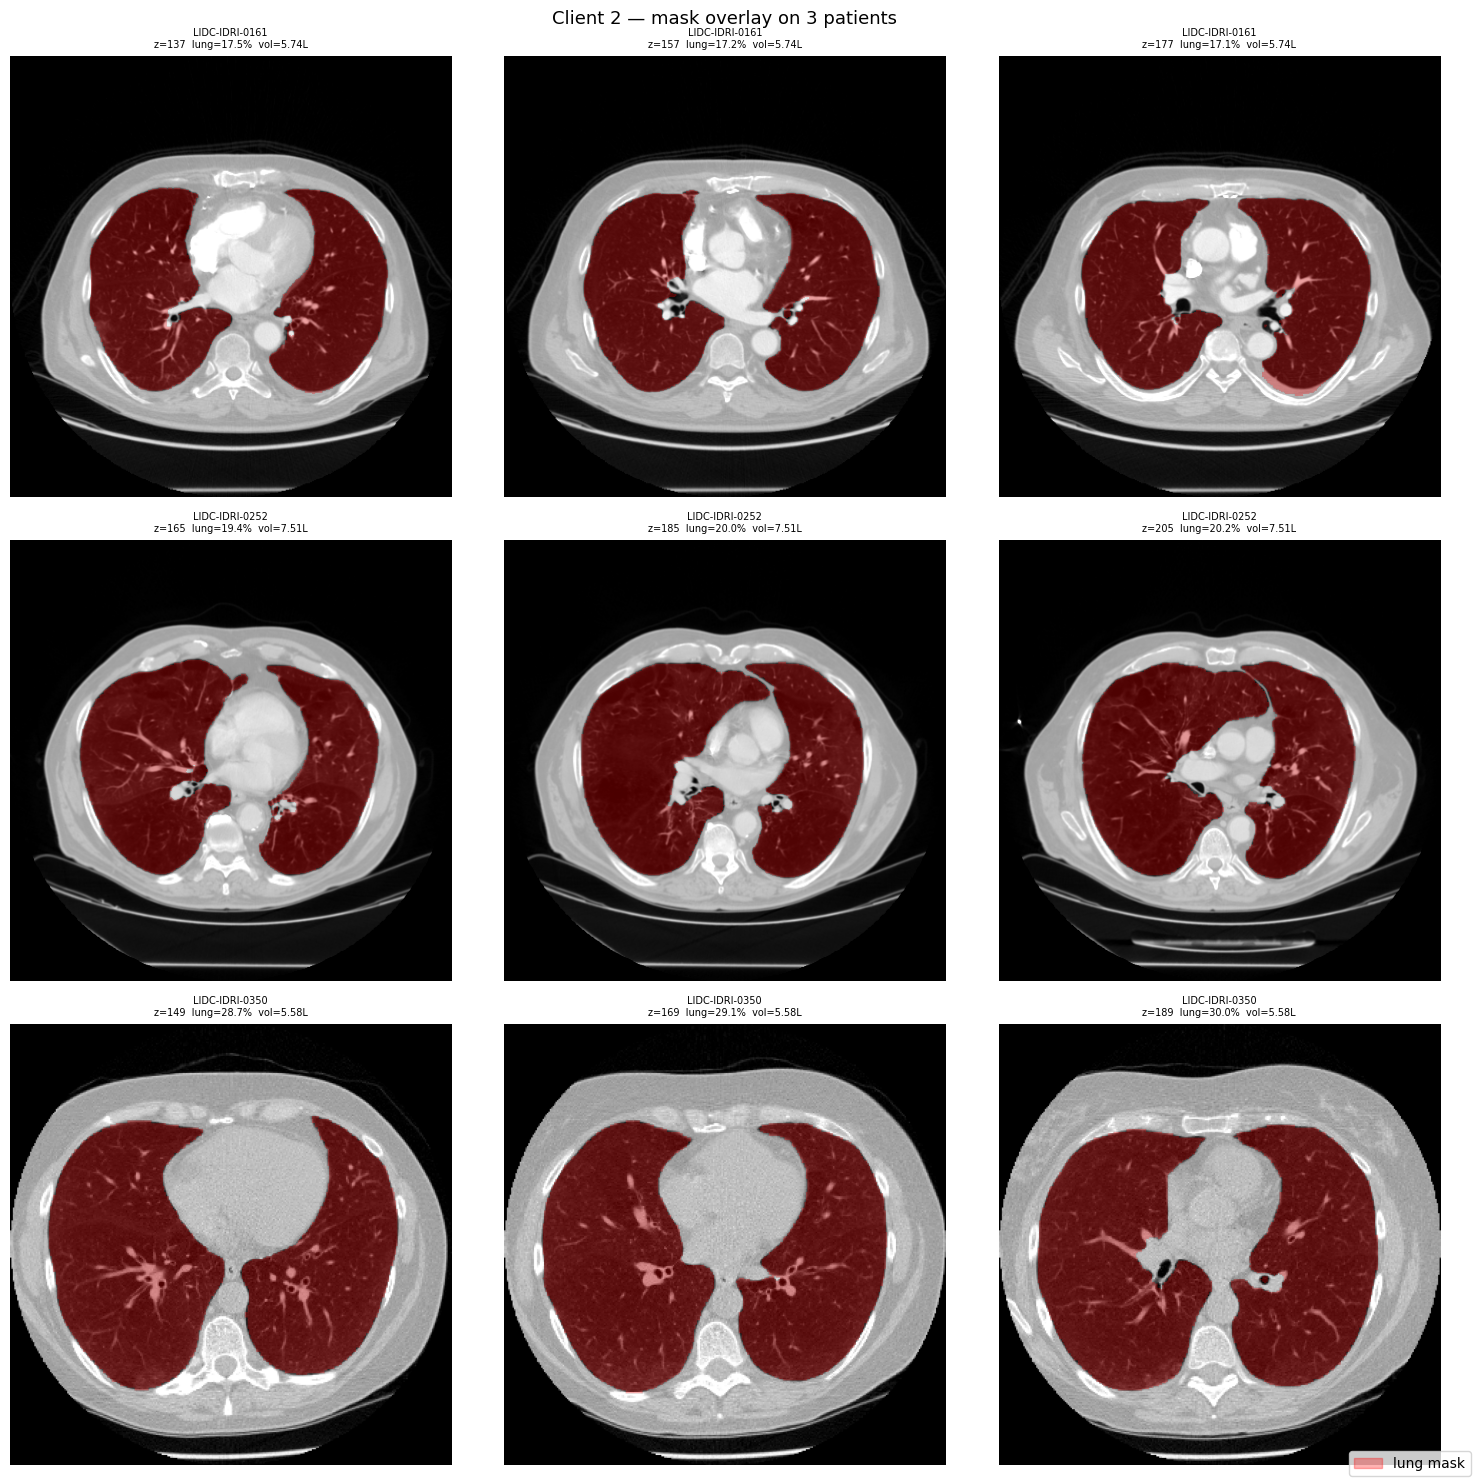

Saved: C:\Users\Administrator\desktop\unet\client2\logs\client2_verify.png

CLIENT 2 SUMMARY
✓ Client 2 fully verified — ready for FL


In [9]:
# VERIFY CLIENT 2 — full quality check
# ============================================================
import numpy as np
import json
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from pathlib import Path

CLIENT_ID = 2
OUT_ROOT   = Path(r"C:\Users\Administrator\desktop\unet")
CLIENT_DIR  = OUT_ROOT / f"client{CLIENT_ID}"
PREPROC_DIR = CLIENT_DIR / "preprocessed"
MASK_DIR    = CLIENT_DIR / "lung_masks"
ANNOT_DIR   = CLIENT_DIR / "annotations"
PATCH_DIR   = CLIENT_DIR / "patches" / f"client{CLIENT_ID}"

# load patient list
with open(OUT_ROOT / "federation_splits.json") as f:
    fed_splits = json.load(f)
CLIENT_PIDS = fed_splits[f"client{CLIENT_ID}_pids"]
print(f"Expected patients: {len(CLIENT_PIDS)}")

# ── Cell 1 check ──────────────────────────────────────────────
print(f"\n{'='*50}")
print(f"CELL 1 — PREPROCESSED VOLUMES")
print(f"{'='*50}")
vol_files  = list(PREPROC_DIR.glob("*.npy"))
meta_files = list(PREPROC_DIR.glob("*_meta.npy"))
vol_files  = [f for f in vol_files if '_meta' not in f.name]
print(f"Volumes    : {len(vol_files)}/{len(CLIENT_PIDS)}")
print(f"Meta files : {len(meta_files)}/{len(CLIENT_PIDS)}")
missing_vols = [pid for pid in CLIENT_PIDS
                if not (PREPROC_DIR/f"{pid}.npy").exists()]
if missing_vols:
    print(f"⚠ Missing: {missing_vols[:5]}")
else:
    print(f"✓ All volumes present")

# sample volume stats
sample_vols = [PREPROC_DIR/f"{pid}.npy"
               for pid in CLIENT_PIDS[:5]
               if (PREPROC_DIR/f"{pid}.npy").exists()]
print(f"\nSample volume shapes:")
for vp in sample_vols:
    vol = np.load(vp)
    pid = vp.stem
    print(f"  {pid}: shape={vol.shape}  "
          f"min={vol.min():.3f}  max={vol.max():.3f}")

# ── Cell 2 check ──────────────────────────────────────────────
print(f"\n{'='*50}")
print(f"CELL 2 — LUNG MASKS")
print(f"{'='*50}")
mask_files = list(MASK_DIR.glob("*.npy"))
print(f"Masks: {len(mask_files)}/{len(CLIENT_PIDS)}")
missing_masks = [pid for pid in CLIENT_PIDS
                 if not (MASK_DIR/f"{pid}.npy").exists()]
if missing_masks:
    print(f"⚠ Missing: {missing_masks[:5]}")
else:
    print(f"✓ All masks present")

# shape match + lung volume check
shape_errors = []
low_vol      = []
high_vol     = []
all_lung_vols = []

for pid in CLIENT_PIDS:
    vp = PREPROC_DIR / f"{pid}.npy"
    mp = MASK_DIR    / f"{pid}.npy"
    if not (vp.exists() and mp.exists()):
        continue
    vol  = np.load(vp)
    mask = np.load(mp)
    if mask.shape != vol.shape:
        shape_errors.append((pid, mask.shape, vol.shape))
        continue
    lung_vol = mask.sum() / 1e6  # liters at 1mm³
    all_lung_vols.append((pid, lung_vol))
    if lung_vol < 1.5:
        low_vol.append((pid, lung_vol))
    elif lung_vol > 8.0:
        high_vol.append((pid, lung_vol))

print(f"Shape mismatches    : {len(shape_errors)}")
print(f"Low lung vol (<1.5L): {len(low_vol)}")
print(f"High lung vol (>8L) : {len(high_vol)}")

if all_lung_vols:
    vols = [v for _,v in all_lung_vols]
    print(f"\nLung volume stats (liters):")
    print(f"  min    : {min(vols):.2f}")
    print(f"  max    : {max(vols):.2f}")
    print(f"  mean   : {np.mean(vols):.2f}")
    print(f"  median : {np.median(vols):.2f}")

if shape_errors:
    print(f"\n⚠ Shape mismatches:")
    for pid,ms,vs in shape_errors:
        print(f"  {pid}: mask={ms} vol={vs}")
else:
    print(f"✓ All mask shapes match volumes")

# ── Cell 3 check ──────────────────────────────────────────────
print(f"\n{'='*50}")
print(f"CELL 3 — ANNOTATIONS")
print(f"{'='*50}")
annot_files = list(ANNOT_DIR.glob("*.json"))
print(f"Annotations: {len(annot_files)}/{len(CLIENT_PIDS)}")

total_consensus = 0
total_ambiguous = 0
clean_patients  = 0
coord_errors    = []

for pid in CLIENT_PIDS:
    ap = ANNOT_DIR / f"{pid}.json"
    vp = PREPROC_DIR / f"{pid}.npy"
    if not (ap.exists() and vp.exists()):
        continue
    with open(ap) as f:
        record = json.load(f)
    vol_shape = np.load(vp).shape
    total_consensus += record["n_consensus_nodules"]
    total_ambiguous += record["n_exclusion_zones"] - \
                       record["n_consensus_nodules"]
    if record["n_consensus_nodules"] == 0:
        clean_patients += 1
    # check coords in bounds
    for nod in record["consensus_nodules"]:
        z,y,x = nod["center_res"]
        if not (0<=z<vol_shape[0] and
                0<=y<vol_shape[1] and
                0<=x<vol_shape[2]):
            coord_errors.append((pid, z,y,x, vol_shape))

print(f"Total consensus nodules : {total_consensus}")
print(f"Total ambiguous         : {total_ambiguous}")
print(f"Clean patients (0 nods) : {clean_patients}")
print(f"Coordinate errors       : {len(coord_errors)}")
if coord_errors:
    for pid,z,y,x,vs in coord_errors[:3]:
        print(f"  {pid}: ({z},{y},{x}) outside {vs}")
else:
    print(f"✓ All nodule coordinates in bounds")

# ── Cell 4 check ──────────────────────────────────────────────
print(f"\n{'='*50}")
print(f"CELL 4 — PATCHES")
print(f"{'='*50}")
POS_DIR = PATCH_DIR / "positives"
NEG_DIR = PATCH_DIR / "negatives"
pos_files = list(POS_DIR.glob("*.npz"))
neg_files = list(NEG_DIR.glob("*.npz"))

print(f"Positives : {len(pos_files)}")
print(f"Negatives : {len(neg_files)}")
print(f"Ratio     : {len(neg_files)/max(len(pos_files),1):.2f}")

# check jitter variety
jitter_counts = {}
for f in pos_files:
    parts = f.stem.split('_j')
    if len(parts) == 2:
        ji = int(parts[1])
        jitter_counts[ji] = jitter_counts.get(ji, 0) + 1
print(f"\nJitter distribution:")
for ji in sorted(jitter_counts.keys()):
    print(f"  j{ji:02d} ({'centered' if ji==0 else 'jittered'}): "
          f"{jitter_counts[ji]} patches")

# sample patch check
import random
sample_pos = random.sample(pos_files, min(3, len(pos_files)))
print(f"\nSample positive patches:")
for f in sample_pos:
    d = np.load(f)
    heat = d['heatmap']
    jitter = d.get('jitter', np.array([0,0,0]))
    print(f"  {f.stem}: shape={d['vol'].shape}  "
          f"heatmap_peak={heat.max():.3f}  "
          f"jitter=({jitter[0]},{jitter[1]},{jitter[2]})")

# ── Cell 4S check ─────────────────────────────────────────────
print(f"\n{'='*50}")
print(f"CELL 4S — SPLIT MANIFEST")
print(f"{'='*50}")
manifest_path = PATCH_DIR / "split_manifest.json"
if not manifest_path.exists():
    print("⚠ split_manifest.json not found")
else:
    with open(manifest_path) as f:
        manifest = json.load(f)
    trn = manifest["trn_pids"]
    val = manifest["val_pids"]
    tst = manifest["tst_pids"]
    print(f"Train patients : {len(trn)}")
    print(f"Val   patients : {len(val)}")
    print(f"Test  patients : {len(tst)}")
    print(f"Train patches  : {len(manifest['train_pos'])} pos  "
          f"{len(manifest['train_neg'])} neg")
    print(f"Val   patches  : {len(manifest['val_pos'])} pos  "
          f"{len(manifest['val_neg'])} neg")

    # zero overlap check
    trn_s = set(trn); val_s = set(val); tst_s = set(tst)
    assert len(trn_s & val_s) == 0, "LEAKAGE train/val"
    assert len(trn_s & tst_s) == 0, "LEAKAGE train/test"
    assert len(val_s & tst_s) == 0, "LEAKAGE val/test"
    print(f"✓ Zero overlap between splits")

# global test pool check
global_path = OUT_ROOT / "global_test_pids.json"
if global_path.exists():
    with open(global_path) as f:
        global_test = json.load(f)
    print(f"\nGlobal test pool: "
          f"{len(global_test['test_pids'])} patients")
    for cid, pids in global_test.get("by_client",{}).items():
        print(f"  {cid}: {len(pids)} patients")

# ── visual mask check (3 patients) ───────────────────────────
print(f"\n{'='*50}")
print(f"VISUAL MASK CHECK")
print(f"{'='*50}")

check_pids = [CLIENT_PIDS[0],
              CLIENT_PIDS[len(CLIENT_PIDS)//2],
              CLIENT_PIDS[-1]]

fig, axes = plt.subplots(3, 3, figsize=(15, 15))
fig.suptitle(f"Client {CLIENT_ID} — mask overlay on 3 patients",
             fontsize=13)

for row, pid in enumerate(check_pids):
    vp = PREPROC_DIR / f"{pid}.npy"
    mp = MASK_DIR    / f"{pid}.npy"
    if not (vp.exists() and mp.exists()):
        continue
    vol  = np.load(vp)
    mask = np.load(mp)
    mid  = vol.shape[0] // 2

    for col, z_offset in enumerate([-20, 0, 20]):
        z  = max(0, min(vol.shape[0]-1, mid+z_offset))
        ax = axes[row][col]
        ax.imshow(vol[z], cmap='gray', vmin=0, vmax=1)
        overlay = np.zeros((*mask[z].shape, 4),
                           dtype=np.float32)
        overlay[mask[z]==1, 0] = 1.0
        overlay[mask[z]==1, 3] = 0.3
        ax.imshow(overlay)
        lung_pct = mask[z].mean() * 100
        lung_vol = mask.sum() / 1e6
        ax.set_title(f"{pid}\nz={z}  "
                     f"lung={lung_pct:.1f}%  "
                     f"vol={lung_vol:.2f}L",
                     fontsize=7)
        ax.axis('off')

red_patch = mpatches.Patch(color='red', alpha=0.3,
                            label='lung mask')
fig.legend(handles=[red_patch], loc='lower right')
plt.tight_layout()
out_path = CLIENT_DIR / "logs" / "client2_verify.png"
plt.savefig(out_path, dpi=80, bbox_inches='tight')
plt.show()
print(f"Saved: {out_path}")

# ── final summary ─────────────────────────────────────────────
print(f"\n{'='*50}")
print(f"CLIENT {CLIENT_ID} SUMMARY")
print(f"{'='*50}")
all_good = (
    len(missing_vols) == 0 and
    len(missing_masks) == 0 and
    len(shape_errors) == 0 and
    len(coord_errors) == 0 and
    len(pos_files) > 0 and
    len(neg_files) > 0 and
    manifest_path.exists()
)
if all_good:
    print(f"✓ Client {CLIENT_ID} fully verified — ready for FL")
else:
    print(f"⚠ Issues found — check above before proceeding")

if we want to revaluate client 2-5 on local perf (baseline, that we already did: the 30 epochs local, like in client1)

In [ ]:
# CELL 5 — UNET TRAINING
# Runtime: ~4-6 hours (30 epochs)
# Writes: WEIGHTS_DIR/client{N}_best.pt
#         WEIGHTS_DIR/client{N}_final.pt
#         LOG_DIR/client{N}_loss.png
# ============================================================
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt

class DoubleConv3D(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv3d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm3d(out_ch), nn.ReLU(inplace=True),
            nn.Conv3d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm3d(out_ch), nn.ReLU(inplace=True))
    def forward(self, x): return self.block(x)

class Down(nn.Module):
    def __init__(self, c1, c2):
        super().__init__()
        self.pool = nn.MaxPool3d(2)
        self.conv = DoubleConv3D(c1, c2)
    def forward(self, x): return self.conv(self.pool(x))

class Up(nn.Module):
    def __init__(self, c1, c2):
        super().__init__()
        self.up   = nn.ConvTranspose3d(c1, c2, 2, stride=2)
        self.conv = DoubleConv3D(c1, c2)
    def forward(self, x, skip):
        return self.conv(torch.cat([skip, self.up(x)], dim=1))

class UNet3D(nn.Module):
    def __init__(self, base_filters=32):
        super().__init__()
        f = base_filters
        self.enc1=DoubleConv3D(1,f); self.enc2=Down(f,f*2)
        self.enc3=Down(f*2,f*4);    self.enc4=Down(f*4,f*8)
        self.bottleneck=Down(f*8,f*16)
        self.dec4=Up(f*16,f*8); self.dec3=Up(f*8,f*4)
        self.dec2=Up(f*4,f*2);  self.dec1=Up(f*2,f)
        self.head=nn.Conv3d(f,1,1)
    def forward(self, x):
        e1=self.enc1(x); e2=self.enc2(e1)
        e3=self.enc3(e2); e4=self.enc4(e3)
        b=self.bottleneck(e4)
        return torch.sigmoid(self.head(
            self.dec1(self.dec2(self.dec3(self.dec4(b,e4),e3),e2),e1)))

class OHEMLoss(nn.Module):
    def __init__(self, neg_pos_ratio=3, min_negatives=1000):
        super().__init__()
        self.npr=neg_pos_ratio; self.mnn=min_negatives
    def forward(self, pred, target):
        loss=0.0
        for i in range(pred.shape[0]):
            p=pred[i,0]; t=target[i,0]
            pm=t>0.01; nm=~pm
            pl=F.binary_cross_entropy(p[pm],t[pm],reduction='mean') if pm.sum()>0 else torch.tensor(0.0,device=pred.device)
            n_neg=min(int(nm.sum()),max(self.mnn,int(pm.sum())*self.npr))
            nl=F.binary_cross_entropy(p[nm],torch.zeros(nm.sum(),device=pred.device),reduction='none').topk(n_neg).values.mean()
            loss+=pl+nl
        return loss/pred.shape[0]

class PatchDataset(Dataset):
    def __init__(self, pos_files, neg_files, augment=False):
        self.augment=augment
        self.items=[(str(f),1) for f in pos_files]+[(str(f),0) for f in neg_files]
        random.shuffle(self.items)
        print(f'  Dataset: {len(pos_files)} pos  {len(neg_files)} neg  total={len(self.items)}')
    def __len__(self): return len(self.items)
    def __getitem__(self, idx):
        path,_=self.items[idx]; d=np.load(path)
        vol=d['vol'].astype(np.float32); heat=d['heatmap'].astype(np.float32)
        if self.augment:
            for ax in range(3):
                if random.random()>0.5:
                    vol=np.flip(vol,axis=ax).copy(); heat=np.flip(heat,axis=ax).copy()
            k=random.randint(0,3)
            vol=np.rot90(vol,k=k,axes=(1,2)).copy(); heat=np.rot90(heat,k=k,axes=(1,2)).copy()
        return torch.from_numpy(vol).unsqueeze(0), torch.from_numpy(heat).unsqueeze(0)

with open(PATCH_DIR / 'split_manifest.json') as f:
    manifest = json.load(f)
train_pos_p=[Path(p) for p in manifest['train_pos']]
train_neg_p=[Path(p) for p in manifest['train_neg']]
val_pos_p  =[Path(p) for p in manifest['val_pos']]
val_neg_p  =[Path(p) for p in manifest['val_neg']]
tst_pids   = manifest['tst_pids']

print('Train set:')
train_ds=PatchDataset(train_pos_p, train_neg_p, augment=True)
print('Val set:')
val_ds  =PatchDataset(val_pos_p,   val_neg_p,   augment=False)
print(f'Test patients: {len(tst_pids)}')

train_loader=DataLoader(train_ds,batch_size=BATCH_SIZE,shuffle=True,num_workers=0,pin_memory=True)
val_loader  =DataLoader(val_ds,  batch_size=BATCH_SIZE,shuffle=False,num_workers=0,pin_memory=True)

model    =UNet3D(base_filters=BASE_FILTERS).to(DEVICE)
criterion=OHEMLoss(neg_pos_ratio=3,min_negatives=1000)
optimizer=torch.optim.Adam(model.parameters(),lr=LR)

from torch.optim.lr_scheduler import SequentialLR,LinearLR,CosineAnnealingLR
warmup   =LinearLR(optimizer,0.1,1.0,total_iters=5)
cosine   =CosineAnnealingLR(optimizer,T_max=N_EPOCHS-5)
scheduler=SequentialLR(optimizer,[warmup,cosine],milestones=[5])

BEST_PT =WEIGHTS_DIR/f'client{CLIENT_ID}_best.pt'
FINAL_PT=WEIGHTS_DIR/f'client{CLIENT_ID}_final.pt'

print(f'\nDevice: {DEVICE}  Params: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}')
print(f'Saving best to: {BEST_PT}')
print(f'\n{"Epoch":>6} {"Train":>10} {"Val":>10} {"LR":>12}')
print('-'*45)

train_losses=[]; val_losses=[]
best_val=float('inf'); patience_cnt=0

for epoch in range(1, N_EPOCHS+1):
    model.train()
    t_loss=0.0; n_batches=len(train_loader)
    for bi,(vol,heat) in enumerate(train_loader):
        vol=vol.to(DEVICE); heat=heat.to(DEVICE)
        optimizer.zero_grad()
        loss=criterion(model(vol),heat)
        loss.backward(); optimizer.step()
        t_loss+=loss.item()
        print(f'\r  Ep {epoch:02d} [{bi+1:03d}/{n_batches:03d}] loss={loss.item():.4f}',end='',flush=True)
    t_loss/=n_batches; scheduler.step()
    model.eval(); v_loss=0.0
    with torch.no_grad():
        for vol,heat in val_loader:
            v_loss+=criterion(model(vol.to(DEVICE)),heat.to(DEVICE)).item()
    v_loss/=len(val_loader)
    train_losses.append(t_loss); val_losses.append(v_loss)
    lr_now=optimizer.param_groups[0]['lr']
    star=''
    if v_loss<best_val:
        best_val=v_loss; patience_cnt=0
        torch.save(model.state_dict(),BEST_PT); star=' ★'
    else:
        patience_cnt+=1
    print(f'\r{"":60}')
    print(f'  Ep {epoch:02d} | train={t_loss:.4f}  val={v_loss:.4f}  lr={lr_now:.6f}{star}',flush=True)
    if patience_cnt>=PATIENCE:
        print(f'\nEarly stopping at epoch {epoch}'); break

torch.save(model.state_dict(),FINAL_PT)
fig,ax=plt.subplots(figsize=(10,5))
ax.plot(train_losses,label='train',color='steelblue',linewidth=2)
ax.plot(val_losses,  label='val',  color='darkorange',linewidth=2)
ax.set_xlabel('Epoch'); ax.set_ylabel('OHEM Loss')
ax.set_title(f'Client {CLIENT_ID} — Loss Curves')
ax.legend(); ax.grid(True,alpha=0.3)
plt.tight_layout()
plt.savefig(LOG_DIR/f'client{CLIENT_ID}_loss.png',dpi=100)
plt.show()
print(f'\nBest val loss : {best_val:.4f}')
print(f'Best weights  : {BEST_PT}')
print(f'Final weights : {FINAL_PT}')


In [ ]:
# CELL 6 — SLIDING WINDOW INFERENCE + FROC
# Max aggregation heatmap, threshold=0.3
# Runtime: ~15-25 min
# Writes: LOG_DIR/all_results.pkl
#         LOG_DIR/all_scores.pkl
#         LOG_DIR/client{N}_test_results.json
#         LOG_DIR/client{N}_test_froc.png
# ============================================================
from scipy.ndimage import maximum_filter
import pickle

model=UNet3D(base_filters=BASE_FILTERS).to(DEVICE)
model.load_state_dict(torch.load(BEST_PT,map_location=DEVICE))
model.eval()
print(f'Model: {BEST_PT}')

with open(PATCH_DIR/'split_manifest.json') as f:
    manifest=json.load(f)
tst_pids=manifest['tst_pids']
print(f'Test patients: {len(tst_pids)}')

def sliding_window_max(model,vol,mask,patch_size,stride,device):
    D,H,W=vol.shape; p=patch_size
    heatmap=np.zeros((D,H,W),dtype=np.float32)
    coords=np.argwhere(mask>0)
    if len(coords)==0: return heatmap
    z1=max(0,coords[:,0].min()-p//4); y1=max(0,coords[:,1].min()-p//4); x1=max(0,coords[:,2].min()-p//4)
    z2=min(D,coords[:,0].max()+p//4); y2=min(H,coords[:,1].max()+p//4); x2=min(W,coords[:,2].max()+p//4)
    model.eval()
    with torch.no_grad():
        for zw in range(z1,z2-p+1,stride):
            for yw in range(y1,y2-p+1,stride):
                for xw in range(x1,x2-p+1,stride):
                    patch=vol[zw:zw+p,yw:yw+p,xw:xw+p]
                    if patch.shape!=(p,p,p): continue
                    if mask[zw:zw+p,yw:yw+p,xw:xw+p].mean()<0.05: continue
                    t=torch.from_numpy(patch).unsqueeze(0).unsqueeze(0).float().to(device)
                    pred=model(t).squeeze().cpu().numpy()
                    heatmap[zw:zw+p,yw:yw+p,xw:xw+p]=np.maximum(heatmap[zw:zw+p,yw:yw+p,xw:xw+p],pred)
    return heatmap

def get_detections(heatmap,threshold=0.3,min_dist=6):
    lm=maximum_filter(heatmap,footprint=np.ones((min_dist,)*3))==heatmap
    lm=lm&(heatmap>threshold)
    c=np.argwhere(lm)
    if len(c)==0: return []
    s=heatmap[lm]; o=np.argsort(s)[::-1]
    return [(int(c[i,0]),int(c[i,1]),int(c[i,2]),float(s[i])) for i in o]

def match_gt(detections,gt_nodules):
    matched=set(); tp,fp=[],[]
    for det in detections:
        dz,dy,dx,sc=det; bd,bi=float('inf'),-1
        for gi,nod in enumerate(gt_nodules):
            if gi in matched: continue
            gz,gy,gx=nod['center_res']
            d=np.sqrt((dz-gz)**2+(dy-gy)**2+(dx-gx)**2)
            if d<max(nod['radius_mm'],10.0) and d<bd: bd,bi=d,gi
        if bi>=0: tp.append({'det':det,'gt':gt_nodules[bi],'dist_mm':bd}); matched.add(bi)
        else: fp.append({'det':det})
    fn=[{'gt':n} for gi,n in enumerate(gt_nodules) if gi not in matched]
    return tp,fp,fn

THRESHOLD=0.3
all_results=[]; all_scores=[]; total_gt=0

for pid in tqdm(tst_pids,desc=f'C{CLIENT_ID} inference'):
    vol =np.load(PREPROC_DIR/f'{pid}.npy')
    mask=np.load(MASK_DIR   /f'{pid}.npy')
    with open(ANNOT_DIR/f'{pid}.json') as f:
        gt_nods=json.load(f)['consensus_nodules']
    total_gt+=len(gt_nods)
    heatmap   =sliding_window_max(model,vol,mask,PATCH_SIZE,STRIDE,DEVICE)
    detections=get_detections(heatmap,THRESHOLD)
    tp,fp,fn  =match_gt(detections,gt_nods)
    all_results.append({'pid':pid,'gt_nodules':len(gt_nods),'detections':len(detections),
                        'tp':len(tp),'fp':len(fp),'fn':len(fn),
                        'tp_list':tp,'fp_list':fp,'fn_list':fn})
    for i in tp: all_scores.append((i['det'][3],1))
    for i in fp: all_scores.append((i['det'][3],0))
    print(f'  {pid}: GT={len(gt_nods):2d} TP={len(tp):2d} FP={len(fp):3d} FN={len(fn):2d}')

with open(LOG_DIR/'all_results.pkl','wb') as f: pickle.dump(all_results,f)
with open(LOG_DIR/'all_scores.pkl','wb') as f:  pickle.dump(all_scores,f)
print(f'Saved: {LOG_DIR}/all_results.pkl')

ttp=sum(r['tp'] for r in all_results); tfp=sum(r['fp'] for r in all_results)
tfn=sum(r['fn'] for r in all_results); ns=len(tst_pids)
sen=ttp/max(ttp+tfn,1); pre=ttp/max(ttp+tfp,1)
f1=2*pre*sen/max(pre+sen,1e-6); fps=tfp/ns

print(f'\n{"="*50}')
print(f'CLIENT {CLIENT_ID} RESULTS  threshold={THRESHOLD}')
print(f'{"="*50}')
print(f'GT={total_gt}  TP={ttp}  FP={tfp}  FN={tfn}')
print(f'Sensitivity : {sen:.3f}  Precision: {pre:.3f}  F1: {f1:.3f}  FP/scan: {fps:.2f}')

cpm=0.0
if all_scores:
    all_scores.sort(key=lambda x:x[0],reverse=True)
    sa=np.array([s[0] for s in all_scores]); la=np.array([s[1] for s in all_scores])
    sl,fl=[],[]
    for th in np.linspace(0.95,0.01,500):
        k=sa>=th
        sl.append(float(la[k].sum()/max(total_gt,1)))
        fl.append(float((1-la[k]).sum()/ns))
    fp_pts=[0.125,0.25,0.5,1,2,4,8]
    cpm_s=[sl[np.argmin([abs(f-fp) for f in fl])] for fp in fp_pts]
    cpm=float(np.mean(cpm_s))
    print(f'\nCPM : {cpm:.3f}')
    for fp_pt,s in zip(fp_pts,cpm_s): print(f'  {fp_pt:5.3f} FP/scan → {s:.3f}')
    fig,axes=plt.subplots(1,2,figsize=(14,6))
    fig.suptitle(f'Client {CLIENT_ID} — {ns} test patients  CPM={cpm:.3f}',fontsize=13)
    axes[0].plot(fl,sl,color='steelblue',linewidth=2)
    axes[0].scatter(fp_pts,cpm_s,color='red',zorder=5,s=80,label=f'CPM={cpm:.3f}')
    axes[0].axhline(0.9,color='gray',linestyle='--',alpha=0.5,label='Sens=0.9')
    axes[0].set_xlabel('FP per scan'); axes[0].set_ylabel('Sensitivity')
    axes[0].set_title('FROC Curve'); axes[0].set_xlim(0,10); axes[0].set_ylim(0,1.05)
    axes[0].legend(); axes[0].grid(True,alpha=0.3)
    ps=[r['pid'].replace('LIDC-IDRI-','') for r in all_results]
    x=np.arange(len(all_results)); w=0.25
    axes[1].bar(x-w,[r['tp'] for r in all_results],w,label='TP',color='green',alpha=0.8)
    axes[1].bar(x,  [r['fp'] for r in all_results],w,label='FP',color='red',  alpha=0.8)
    axes[1].bar(x+w,[r['fn'] for r in all_results],w,label='FN',color='orange',alpha=0.8)
    axes[1].set_xticks(x); axes[1].set_xticklabels(ps,rotation=90,fontsize=7)
    axes[1].set_ylabel('Count'); axes[1].set_title('Per-patient TP/FP/FN')
    axes[1].legend(); axes[1].grid(True,alpha=0.3,axis='y')
    plt.tight_layout()
    plt.savefig(LOG_DIR/f'client{CLIENT_ID}_test_froc.png',dpi=100,bbox_inches='tight')
    plt.show()

with open(LOG_DIR/f'client{CLIENT_ID}_test_results.json','w') as f:
    json.dump({'client_id':CLIENT_ID,'stride':STRIDE,'threshold':THRESHOLD,
               'aggregation':'max','n_patients':ns,'total_gt':total_gt,
               'total_tp':ttp,'total_fp':tfp,'total_fn':tfn,
               'sensitivity':round(sen,4),'precision':round(pre,4),
               'f1':round(f1,4),'fp_per_scan':round(fps,4),'cpm':round(cpm,4),
               'per_patient':[{k:v for k,v in r.items()
                               if k not in ('tp_list','fp_list','fn_list')}
                              for r in all_results]},f,indent=2)
print(f'\nResults: {LOG_DIR}/client{CLIENT_ID}_test_results.json')
print(f'FROC   : {LOG_DIR}/client{CLIENT_ID}_test_froc.png')
print(f'Weights: {BEST_PT}')
